In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

In [11]:
df_deaths_cause = pd.read_csv("/Data/deaths_cause/share-of-deaths-from-major-causes.csv")
df_deaths_cause

FileNotFoundError: [Errno 2] No such file or directory: 'HU/Streamlit_HeartAttack/Data/deaths_cause/share-of-deaths-from-major-causes.csv'

In [541]:
# df_deaths_cause = df_deaths_cause.dropna()
# df_deaths_cause

In [542]:
df_deaths_cause.columns

Index(['Entity', 'Code', 'Year', 'digestive diseases',
       'infectious and parasitic diseases', 'respiratory diseases',
       'diabetes mellitus, blood and endocrine disorders',
       'intentional injuries', 'perinatal conditions',
       'respiratory infections', 'neuropsychiatric conditions',
       'malignant neoplasms', 'cardiovascular diseases',
       'ill-defined injuries', 'musculoskeletal diseases',
       'congenital anomalies', 'maternal conditions',
       'nutritional deficiencies', 'other neoplasms', 'skin diseases',
       'unintentional injuries'],
      dtype='object')

In [543]:
# Define the text to remove
remove_text = "Share of total deaths in both sexes in those aged all ages that are from "

# Rename columns by replacing the unwanted text
df_deaths_cause.columns = df_deaths_cause.columns.str.replace(remove_text, "", regex=False)

# Display updated column names
print(df_deaths_cause.columns)

Index(['Entity', 'Code', 'Year', 'digestive diseases',
       'infectious and parasitic diseases', 'respiratory diseases',
       'diabetes mellitus, blood and endocrine disorders',
       'intentional injuries', 'perinatal conditions',
       'respiratory infections', 'neuropsychiatric conditions',
       'malignant neoplasms', 'cardiovascular diseases',
       'ill-defined injuries', 'musculoskeletal diseases',
       'congenital anomalies', 'maternal conditions',
       'nutritional deficiencies', 'other neoplasms', 'skin diseases',
       'unintentional injuries'],
      dtype='object')


In [544]:
df_deaths_cause

,Entity,Code,Year,digestive diseases,infectious and parasitic diseases,respiratory diseases,"diabetes mellitus, blood and endocrine disorders",intentional injuries,perinatal conditions,respiratory infections,...,malignant neoplasms,cardiovascular diseases,ill-defined injuries,musculoskeletal diseases,congenital anomalies,maternal conditions,nutritional deficiencies,other neoplasms,skin diseases,unintentional injuries
0,Albania,ALB,1987,3.884336,2.447189,2.972411,0.888838,0.675286,1.569895,12.541844,...,10.931548,36.869446,0.069260,0.000000,0.854208,0.150063,0.571396,0.842664,0.357844,3.503405
1,Albania,ALB,1988,3.716784,2.095756,3.108898,0.937880,0.648411,1.765762,10.745093,...,12.597696,38.134663,0.057894,0.000000,0.665779,0.162103,0.636832,0.955248,0.254733,3.763098
2,Albania,ALB,1989,3.682096,2.999615,2.873025,0.897132,0.754032,1.375970,12.840552,...,11.321482,37.420883,0.027519,0.000000,0.682481,0.187132,0.473334,0.979691,0.132093,3.847212
3,Albania,ALB,1992,3.364660,1.908574,2.807750,1.044205,1.026801,1.456085,11.822718,...,10.436246,36.668987,0.139227,0.000000,0.893375,0.058011,0.458290,1.061608,0.116023,5.012182
4,Albania,ALB,1993,3.551896,2.548230,3.347557,1.153916,1.664764,0.841397,12.783220,...,9.862371,35.597090,0.330549,0.276459,0.853417,0.096160,0.619028,1.899153,0.204339,5.937857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4937,World Wide,WW,2018,376.428066,238.568250,407.648806,418.752814,157.402503,84.816096,347.492628,...,1683.171485,3008.887560,40.230343,38.271859,52.370825,5.194548,33.233016,54.693757,31.662403,357.275396
4938,World Wide,WW,2019,365.920930,227.654765,414.648090,426.308788,144.811061,77.327997,347.078452,...,1704.029175,2856.676472,41.048519,36.804173,51.887663,4.643430,30.809633,56.527202,31.960265,337.838543
4939,World Wide,WW,2020,265.788180,145.021537,291.025204,328.769963,113.973568,45.831929,726.882470,...,1337.956062,2064.639312,24.075945,28.626501,31.751503,2.715771,23.084114,42.333149,23.471697,228.650621
4940,World Wide,WW,2021,196.472112,105.789997,200.534455,261.593655,77.187129,33.876985,790.847409,...,899.727780,1586.222063,17.660785,19.940606,22.036062,2.830995,16.273567,29.250595,16.557977,175.500868


In [545]:
# Bereken "World Wide" door alle landen op te tellen
world_wide = df_deaths_cause.groupby("Year").sum(numeric_only=True)
world_wide["Entity"] = "World Wide"
world_wide["Code"] = "WW"

# Voeg "World Wide" toe aan de originele DataFrame
world_wide = world_wide.reset_index()  # Reset de index zodat "Year" een gewone kolom is
final_df = pd.concat([df_deaths_cause, world_wide], ignore_index=True)

In [546]:
final_df

,Entity,Code,Year,digestive diseases,infectious and parasitic diseases,respiratory diseases,"diabetes mellitus, blood and endocrine disorders",intentional injuries,perinatal conditions,respiratory infections,...,malignant neoplasms,cardiovascular diseases,ill-defined injuries,musculoskeletal diseases,congenital anomalies,maternal conditions,nutritional deficiencies,other neoplasms,skin diseases,unintentional injuries
0,Albania,ALB,1987,3.884336,2.447189,2.972411,0.888838,0.675286,1.569895,12.541844,...,10.931548,36.869446,0.069260,0.000000,0.854208,0.150063,0.571396,0.842664,0.357844,3.503405
1,Albania,ALB,1988,3.716784,2.095756,3.108898,0.937880,0.648411,1.765762,10.745093,...,12.597696,38.134663,0.057894,0.000000,0.665779,0.162103,0.636832,0.955248,0.254733,3.763098
2,Albania,ALB,1989,3.682096,2.999615,2.873025,0.897132,0.754032,1.375970,12.840552,...,11.321482,37.420883,0.027519,0.000000,0.682481,0.187132,0.473334,0.979691,0.132093,3.847212
3,Albania,ALB,1992,3.364660,1.908574,2.807750,1.044205,1.026801,1.456085,11.822718,...,10.436246,36.668987,0.139227,0.000000,0.893375,0.058011,0.458290,1.061608,0.116023,5.012182
4,Albania,ALB,1993,3.551896,2.548230,3.347557,1.153916,1.664764,0.841397,12.783220,...,9.862371,35.597090,0.330549,0.276459,0.853417,0.096160,0.619028,1.899153,0.204339,5.937857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5010,World Wide,WW,2018,752.856131,477.136501,815.297612,837.505628,314.805006,169.632192,694.985256,...,3366.342970,6017.775120,80.460686,76.543717,104.741649,10.389095,66.466032,109.387513,63.324806,714.550792
5011,World Wide,WW,2019,731.841860,455.309530,829.296179,852.617576,289.622123,154.655994,694.156904,...,3408.058350,5713.352944,82.097038,73.608346,103.775326,9.286861,61.619267,113.054404,63.920530,675.677085
5012,World Wide,WW,2020,531.576360,290.043073,582.050409,657.539925,227.947135,91.663858,1453.764940,...,2675.912123,4129.278624,48.151889,57.253003,63.503005,5.431542,46.168229,84.666298,46.943394,457.301242
5013,World Wide,WW,2021,392.944224,211.579994,401.068909,523.187309,154.374257,67.753970,1581.694819,...,1799.455559,3172.444126,35.321571,39.881211,44.072124,5.661990,32.547133,58.501191,33.115953,351.001736


In [547]:
final_df[final_df["Entity"] == "World Wide"]

,Entity,Code,Year,digestive diseases,infectious and parasitic diseases,respiratory diseases,"diabetes mellitus, blood and endocrine disorders",intentional injuries,perinatal conditions,respiratory infections,...,malignant neoplasms,cardiovascular diseases,ill-defined injuries,musculoskeletal diseases,congenital anomalies,maternal conditions,nutritional deficiencies,other neoplasms,skin diseases,unintentional injuries
4869,World Wide,WW,1950,30.793358,70.660342,20.675103,18.607839,10.089020,38.930262,44.482599,...,125.138614,367.368549,0.000000,3.961684,11.012941,2.401942,4.584261,4.103711,0.584004,39.060040
4870,World Wide,WW,1951,58.739141,127.062322,40.560440,33.872095,21.235577,74.223059,112.027514,...,239.099801,662.961120,0.000000,7.208554,18.072463,4.905774,8.878289,9.467121,0.934879,76.471796
4871,World Wide,WW,1952,63.648259,118.916581,39.348635,34.906524,24.363860,78.130424,93.604331,...,267.916843,733.115178,0.000000,7.430073,19.725264,4.988606,8.744766,9.568472,0.907076,82.186149
4872,World Wide,WW,1953,66.149465,123.703085,42.730146,37.325984,27.623822,85.659847,113.120231,...,272.189389,755.709691,0.000000,8.356295,20.162783,5.627438,10.776820,10.117712,1.085442,89.945646
4873,World Wide,WW,1954,73.543081,119.257028,46.356850,39.424437,29.899687,87.594165,99.025089,...,298.796005,818.432233,0.000000,8.776175,22.223592,6.406039,13.048721,10.727067,1.191229,94.159174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5010,World Wide,WW,2018,752.856131,477.136501,815.297612,837.505628,314.805006,169.632192,694.985256,...,3366.342970,6017.775120,80.460686,76.543717,104.741649,10.389095,66.466032,109.387513,63.324806,714.550792
5011,World Wide,WW,2019,731.841860,455.309530,829.296179,852.617576,289.622123,154.655994,694.156904,...,3408.058350,5713.352944,82.097038,73.608346,103.775326,9.286861,61.619267,113.054404,63.920530,675.677085
5012,World Wide,WW,2020,531.576360,290.043073,582.050409,657.539925,227.947135,91.663858,1453.764940,...,2675.912123,4129.278624,48.151889,57.253003,63.503005,5.431542,46.168229,84.666298,46.943394,457.301242
5013,World Wide,WW,2021,392.944224,211.579994,401.068909,523.187309,154.374257,67.753970,1581.694819,...,1799.455559,3172.444126,35.321571,39.881211,44.072124,5.661990,32.547133,58.501191,33.115953,351.001736


In [548]:
# filename = "final.csv"
# final_df.to_csv(filename, index=False)
# df_exported = pd.read_csv(filename)
# df_exported

In [549]:
df_deaths_cause['Entity'].unique()

array(['Albania', 'Antigua and Barbuda', 'Argentina', 'Armenia',
       'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain',
       'Barbados', 'Belarus', 'Belgium', 'Belize',
       'Bosnia and Herzegovina', 'Brazil', 'Brunei', 'Bulgaria', 'Canada',
       'Cape Verde', 'Chile', 'Colombia', 'Costa Rica', 'Croatia', 'Cuba',
       'Cyprus', 'Czechia', 'Denmark', 'Dominica', 'Dominican Republic',
       'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Fiji', 'Finland',
       'France', 'French Guiana', 'Georgia', 'Germany', 'Greece',
       'Grenada', 'Guadeloupe', 'Guatemala', 'Guyana', 'Hong Kong',
       'Hungary', 'Iceland', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy',
       'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kuwait', 'Kyrgyzstan',
       'Latvia', 'Lebanon', 'Lithuania', 'Luxembourg', 'Malaysia',
       'Maldives', 'Malta', 'Martinique', 'Mauritius', 'Mayotte',
       'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Netherlands',
       'New Zealand', 'Nicaragua', '

In [550]:
# Group by 'Entity' to get the total per country
df_grouped = df_deaths_cause.groupby("Entity", as_index=False).sum(numeric_only=True)

# Calculate worldwide total by summing all countries
worldwide_total = df_grouped.drop(columns=["Entity"]).sum()

# Add a row for the worldwide total
worldwide_total["Entity"] = "Worldwide"  # Set entity name
df_grouped = pd.concat([df_grouped, pd.DataFrame([worldwide_total])], ignore_index=True)

# Show the updated DataFrame
df_grouped


,Entity,Year,digestive diseases,infectious and parasitic diseases,respiratory diseases,"diabetes mellitus, blood and endocrine disorders",intentional injuries,perinatal conditions,respiratory infections,neuropsychiatric conditions,malignant neoplasms,cardiovascular diseases,ill-defined injuries,musculoskeletal diseases,congenital anomalies,maternal conditions,nutritional deficiencies,other neoplasms,skin diseases,unintentional injuries
0,Albania,43983.0,54.662748,25.948582,59.911595,20.017848,42.779214,21.383278,125.482939,59.188303,304.881685,1012.896895,4.178982,3.581346,12.429508,1.157451,8.187990,23.740992,1.867940,100.319305
1,Antigua and Barbuda,101652.0,177.125241,287.348634,110.115256,338.579663,18.268736,148.278664,249.075141,138.338870,780.608167,1860.105542,27.711539,16.795331,36.759390,13.113618,84.294013,23.410308,35.809841,189.181916
2,Argentina,99795.0,224.083188,225.235494,294.892984,110.499285,76.892870,131.950148,269.554332,88.775233,898.625428,1813.859072,43.355858,11.908214,50.313319,7.314756,32.823161,31.862703,13.128962,201.780658
3,Armenia,76087.0,166.354749,54.004690,171.333492,141.001964,36.563895,42.558719,149.295474,29.977454,639.600625,1904.943956,55.897670,6.244942,36.586206,2.114976,0.398880,5.947324,2.362238,176.246989
4,Australia,142973.0,225.693568,101.644901,359.862844,207.736644,130.911575,98.842375,191.378803,346.180170,1608.026523,3192.769746,6.810637,41.488550,58.510493,3.246126,19.116899,29.573974,10.643988,347.844742
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,Uruguay,119279.0,233.748167,195.555178,258.949877,137.001594,115.123395,162.163612,196.359397,227.964674,1309.632850,2116.249651,1.183636,23.003471,51.035499,6.614216,41.601292,33.449992,16.654817,261.112016
117,Uzbekistan,68012.0,174.970892,160.601768,112.162598,72.137149,57.563311,96.753069,327.934587,56.656125,267.244046,1710.462769,16.958287,4.390997,30.864077,4.346022,1.165124,2.838039,1.883586,181.887620
118,Venezuela,117131.0,203.956808,583.195628,148.606897,180.599051,238.598687,383.280836,287.848833,78.414344,648.992774,1372.260908,120.267802,19.297160,100.556251,25.362126,67.155052,36.935300,8.320529,459.978881
119,World Wide,144978.0,20285.586493,20874.357565,19413.008276,15721.988167,10164.776633,11325.928573,23389.487859,14378.877281,83380.682181,182021.229127,2946.819394,1754.042646,4278.473309,657.597322,3328.233229,2136.897796,1115.710064,23588.371069


In [551]:
# df_grouped = df_grouped.set_index("Entity")
# df_grouped

In [552]:
# filename = "diseases_by_country.csv"
# df_grouped.to_csv(filename, index=False)
# df_exported = pd.read_csv(filename)
# df_exported

In [553]:
#World wide

# Select columns to group by (all except 'Entity', 'Code', 'Year')
group_by_cols = [col for col in df_deaths_cause.columns if col not in ['Entity', 'Code', 'Year']]

# Perform the groupby operation and aggregate (e.g., sum)
df_grouped = df_deaths_cause.groupby(group_by_cols).sum().reset_index()

# Display the grouped dataframe
df_grouped.head()

,digestive diseases,infectious and parasitic diseases,respiratory diseases,"diabetes mellitus, blood and endocrine disorders",intentional injuries,perinatal conditions,respiratory infections,neuropsychiatric conditions,malignant neoplasms,cardiovascular diseases,ill-defined injuries,musculoskeletal diseases,congenital anomalies,maternal conditions,nutritional deficiencies,other neoplasms,skin diseases,unintentional injuries,Year
0,0.568182,3.125000,6.439394,3.787879,0.378788,3.693182,1.136364,1.893939,5.208334,30.776516,8.428030,0.189394,0.189394,0.284091,1.231061,0.000000,0.000000,1.609849,2001
1,0.908174,8.375379,6.962664,2.119072,0.100908,2.219980,0.403633,0.908174,3.430878,18.365288,30.978810,0.000000,0.504541,0.201816,0.100908,0.605449,0.100908,10.595358,2004
2,1.031746,5.714286,12.539682,4.603175,0.634921,2.857143,2.777778,2.460317,5.396825,37.380950,1.587302,0.158730,0.317460,0.158730,0.634921,0.714286,0.476190,1.666667,2016
3,1.093439,2.385686,9.244533,2.584493,0.397614,2.286282,1.689861,3.280318,3.976143,41.948310,5.765408,0.000000,0.198807,0.000000,0.695825,0.099404,0.198807,2.087475,2003
4,1.103753,4.194261,2.869757,5.960265,0.441501,4.415011,1.103753,3.973510,15.894040,18.763798,0.000000,0.220751,4.635762,0.220751,0.220751,0.220751,0.000000,8.388521,2012


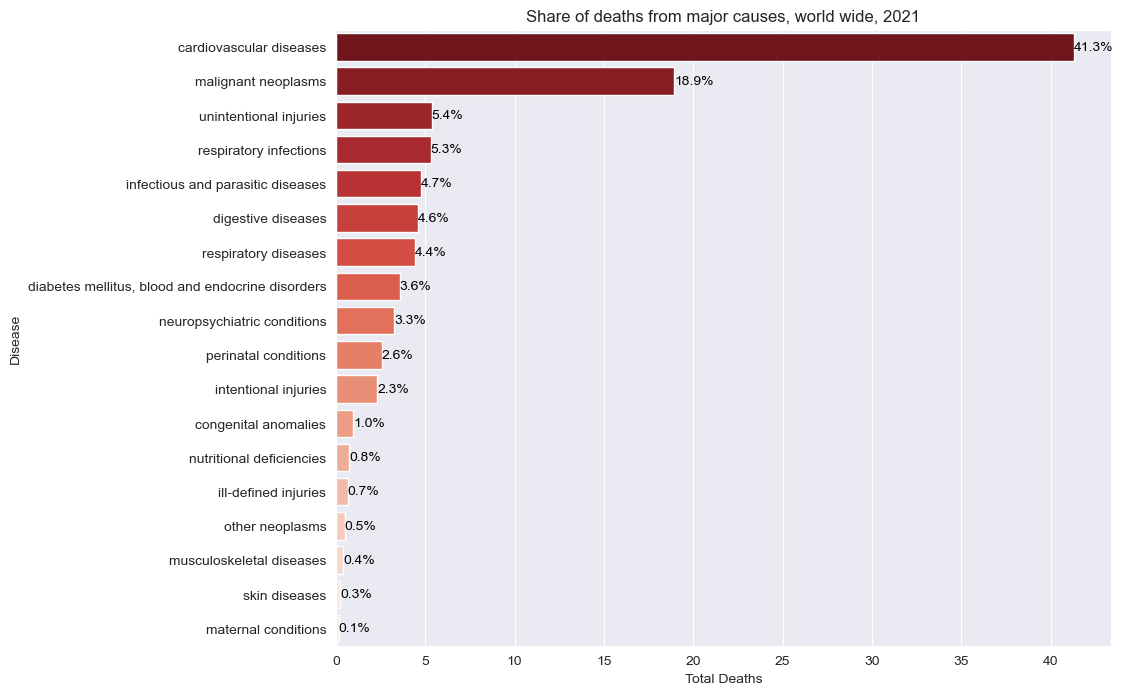

In [554]:
# Exclude 'Entity', 'Code', 'Year' and sum up the values per disease
df_disease = df_deaths_cause.drop(columns=['Entity', 'Code', 'Year']).sum()

# Convert to percentage
df_disease_percentage = (df_disease / df_disease.sum()) * 100

# Sort in descending order
df_disease_percentage = df_disease_percentage.sort_values(ascending=False)

# Set figure size
plt.figure(figsize=(10, 8))

# Create horizontal barplot
ax = sns.barplot(y=df_disease_percentage.index, x=df_disease_percentage.values, palette="Reds_r")

# Add percentage labels on bars
for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}%',  # Format as percentage
                (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10, color='black')

# Add labels and title
plt.ylabel("Disease")
plt.xlabel("Total Deaths")
plt.title("Share of deaths from major causes, world wide, 2021")

# Show plot
plt.show()


# Death cause by type

In [555]:
df_deaths_cause_by_type = pd.read_csv('C:/Users/daanv/Custom Datascience Projects/HU/Streamlit_HeartAttack/Data/deaths_cardiovascular_types/deaths-from-cardiovascular-disease-type.csv')

In [556]:
df_deaths_cause_by_type

,Entity,Code,Year,rheumatic heart disease,"cardiomyopathy, myocarditis, endocarditis",other circulatory diseases,hypertensive heart disease,ischaemic stroke,haemorrhagic stroke,ischaemic heart disease
0,Afghanistan,AFG,2000,729.0,318.0,1037.0,4981.0,5610.0,9032.0,21035.0
1,Afghanistan,AFG,2001,718.0,329.0,1079.0,5080.0,5755.0,9138.0,21233.0
2,Afghanistan,AFG,2002,735.0,343.0,1163.0,5417.0,6218.0,9360.0,22092.0
3,Afghanistan,AFG,2003,876.0,412.0,1409.0,5794.0,6770.0,9930.0,23224.0
4,Afghanistan,AFG,2004,874.0,424.0,1464.0,6011.0,7127.0,9993.0,23834.0
...,...,...,...,...,...,...,...,...,...,...
4417,Zimbabwe,ZWE,2017,700.0,993.0,1133.0,2651.0,3395.0,5795.0,6502.0
4418,Zimbabwe,ZWE,2018,754.0,1049.0,1198.0,2744.0,3488.0,5997.0,6749.0
4419,Zimbabwe,ZWE,2019,734.0,1038.0,1199.0,2737.0,3487.0,5907.0,6686.0
4420,Zimbabwe,ZWE,2020,741.0,1131.0,1301.0,2996.0,3889.0,6403.0,7365.0


In [557]:
# Define the text to remove
remove_text = "Total deaths from "

# Rename columns by replacing the unwanted text
df_deaths_cause_by_type.columns = df_deaths_cause_by_type.columns.str.replace(remove_text, "", regex=False)

# Display updated column names
print(df_deaths_cause_by_type.columns)

Index(['Entity', 'Code', 'Year', 'rheumatic heart disease',
       'cardiomyopathy, myocarditis, endocarditis',
       'other circulatory diseases', 'hypertensive heart disease',
       'ischaemic stroke', 'haemorrhagic stroke', 'ischaemic heart disease'],
      dtype='object')


In [558]:
# Define the text to remove
remove_text = " among both sexes"

# Rename columns by replacing the unwanted text
df_deaths_cause_by_type.columns = df_deaths_cause_by_type.columns.str.replace(remove_text, "", regex=False)

# Display updated column names
print(df_deaths_cause_by_type.columns)

Index(['Entity', 'Code', 'Year', 'rheumatic heart disease',
       'cardiomyopathy, myocarditis, endocarditis',
       'other circulatory diseases', 'hypertensive heart disease',
       'ischaemic stroke', 'haemorrhagic stroke', 'ischaemic heart disease'],
      dtype='object')


In [559]:
df_deaths_cause_by_type = df_deaths_cause_by_type.round()

In [560]:
df_deaths_cause_by_type

,Entity,Code,Year,rheumatic heart disease,"cardiomyopathy, myocarditis, endocarditis",other circulatory diseases,hypertensive heart disease,ischaemic stroke,haemorrhagic stroke,ischaemic heart disease
0,Afghanistan,AFG,2000,729.0,318.0,1037.0,4981.0,5610.0,9032.0,21035.0
1,Afghanistan,AFG,2001,718.0,329.0,1079.0,5080.0,5755.0,9138.0,21233.0
2,Afghanistan,AFG,2002,735.0,343.0,1163.0,5417.0,6218.0,9360.0,22092.0
3,Afghanistan,AFG,2003,876.0,412.0,1409.0,5794.0,6770.0,9930.0,23224.0
4,Afghanistan,AFG,2004,874.0,424.0,1464.0,6011.0,7127.0,9993.0,23834.0
...,...,...,...,...,...,...,...,...,...,...
4417,Zimbabwe,ZWE,2017,700.0,993.0,1133.0,2651.0,3395.0,5795.0,6502.0
4418,Zimbabwe,ZWE,2018,754.0,1049.0,1198.0,2744.0,3488.0,5997.0,6749.0
4419,Zimbabwe,ZWE,2019,734.0,1038.0,1199.0,2737.0,3487.0,5907.0,6686.0
4420,Zimbabwe,ZWE,2020,741.0,1131.0,1301.0,2996.0,3889.0,6403.0,7365.0


In [561]:
df_deaths_cause_by_type["Entity"].unique()

array(['Afghanistan', 'Africa', 'Albania', 'Algeria', 'Andorra', 'Angola',
       'Antigua and Barbuda', 'Argentina', 'Armenia', 'Asia', 'Australia',
       'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh',
       'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bhutan',
       'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil',
       'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia',
       'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic',
       'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo',
       'Cook Islands', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba',
       'Cyprus', 'Czechia', 'Democratic Republic of Congo', 'Denmark',
       'Djibouti', 'Dominica', 'Dominican Republic', 'East Timor',
       'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Eritrea',
       'Estonia', 'Eswatini', 'Ethiopia', 'Europe', 'Fiji', 'Finland',
       'France', 'Gabon', 'Gambia', 'Georgia', 'Germany', 'Ghana',
       'Greece', 'G

In [577]:
# filename = "deaths_cardiovascular_by_type.csv"
# df_deaths_cause_by_type.to_csv(filename, index=False)
# df_exported = pd.read_csv(filename)
# df_exported

---

# Ischaemic heart disease

In [580]:
# df_ischaemic_heart_disease = pd.read_csv("C:/Users/daanv/Custom Datascience Projects/HU/Streamlit_HeartAttack/Data/Ischaemic_heart_disease/death-rate-from-ischaemic-heart-disease-who-ghe-age-standardized.csv")
df_ischaemic_heart_disease = df_deaths_cause_by_type[['Entity', 'Code', 'Year', 'ischaemic heart disease']]
df_ischaemic_heart_disease


,Entity,Code,Year,ischaemic heart disease
0,Afghanistan,AFG,2000,21035.0
1,Afghanistan,AFG,2001,21233.0
2,Afghanistan,AFG,2002,22092.0
3,Afghanistan,AFG,2003,23224.0
4,Afghanistan,AFG,2004,23834.0
...,...,...,...,...
4417,Zimbabwe,ZWE,2017,6502.0
4418,Zimbabwe,ZWE,2018,6749.0
4419,Zimbabwe,ZWE,2019,6686.0
4420,Zimbabwe,ZWE,2020,7365.0


In [581]:
df_ischaemic_heart_disease[df_ischaemic_heart_disease["Entity"] == "World"]

,Entity,Code,Year,ischaemic heart disease
4334,World,OWID_WRL,2000,6356050.0
4335,World,OWID_WRL,2001,6445742.0
4336,World,OWID_WRL,2002,6641268.0
4337,World,OWID_WRL,2003,6866501.0
4338,World,OWID_WRL,2004,6878148.0
4339,World,OWID_WRL,2005,7039916.0
4340,World,OWID_WRL,2006,7015929.0
4341,World,OWID_WRL,2007,7125245.0
4342,World,OWID_WRL,2008,7299885.0
4343,World,OWID_WRL,2009,7397162.0


In [582]:
# def get_coordinates(country_name):
# 	geolocator = Nominatim(user_agent="geoapi")
# 	location = geolocator.geocode(country_name)
# 	if location:
# 		return location.latitude, location.longitude
# 	else:
# 		return None, None
#
# # Voeg coördinaten toe aan de dataset
# df_ischaemic_heart_disease["Coordinates"] = df_ischaemic_heart_disease["Entity"].apply(get_coordinates)
# df_ischaemic_heart_disease[["Latitude", "Longitude"]] = pd.DataFrame(df_ischaemic_heart_disease["Coordinates"].tolist(), index=df_ischaemic_heart_disease.index)
#
# df_ischaemic_heart_disease

In [583]:
# Set up geolocator and rate limiter for handling multiple requests
geolocator = Nominatim(user_agent="geoapi")
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)  # Avoid exceeding usage limits

# Fetch coordinates for unique country names
unique_countries = df_ischaemic_heart_disease["Entity"].unique()
country_coords = {}

for country in unique_countries:
    location = geocode(country)
    if location:
        country_coords[country] = (location.latitude, location.longitude)
    else:
        country_coords[country] = (None, None)  # Handle countries with missing data

# Map the fetched coordinates back to the DataFrame
df_ischaemic_heart_disease["Latitude"] = df_ischaemic_heart_disease["Entity"].map(lambda x: country_coords[x][0])
df_ischaemic_heart_disease["Longitude"] = df_ischaemic_heart_disease["Entity"].map(lambda x: country_coords[x][1])

# Display the resulting DataFrame
print(df_ischaemic_heart_disease)

           Entity Code  Year  ischaemic heart disease   Latitude  Longitude
0     Afghanistan  AFG  2000                  21035.0  33.768006  66.238514
1     Afghanistan  AFG  2001                  21233.0  33.768006  66.238514
2     Afghanistan  AFG  2002                  22092.0  33.768006  66.238514
3     Afghanistan  AFG  2003                  23224.0  33.768006  66.238514
4     Afghanistan  AFG  2004                  23834.0  33.768006  66.238514
...           ...  ...   ...                      ...        ...        ...
4417     Zimbabwe  ZWE  2017                   6502.0 -18.455496  29.746841
4418     Zimbabwe  ZWE  2018                   6749.0 -18.455496  29.746841
4419     Zimbabwe  ZWE  2019                   6686.0 -18.455496  29.746841
4420     Zimbabwe  ZWE  2020                   7365.0 -18.455496  29.746841
4421     Zimbabwe  ZWE  2021                   7116.0 -18.455496  29.746841

[4422 rows x 6 columns]


C:\Users\daanv\AppData\Local\Temp\ipykernel_16480\4018567211.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ischaemic_heart_disease["Latitude"] = df_ischaemic_heart_disease["Entity"].map(lambda x: country_coords[x][0])
C:\Users\daanv\AppData\Local\Temp\ipykernel_16480\4018567211.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ischaemic_heart_disease["Longitude"] = df_ischaemic_heart_disease["Entity"].map(lambda x: country_coords[x][1])


In [584]:
df_ischaemic_heart_disease

,Entity,Code,Year,ischaemic heart disease,Latitude,Longitude
0,Afghanistan,AFG,2000,21035.0,33.768006,66.238514
1,Afghanistan,AFG,2001,21233.0,33.768006,66.238514
2,Afghanistan,AFG,2002,22092.0,33.768006,66.238514
3,Afghanistan,AFG,2003,23224.0,33.768006,66.238514
4,Afghanistan,AFG,2004,23834.0,33.768006,66.238514
...,...,...,...,...,...,...
4417,Zimbabwe,ZWE,2017,6502.0,-18.455496,29.746841
4418,Zimbabwe,ZWE,2018,6749.0,-18.455496,29.746841
4419,Zimbabwe,ZWE,2019,6686.0,-18.455496,29.746841
4420,Zimbabwe,ZWE,2020,7365.0,-18.455496,29.746841


In [585]:
df_ischaemic_heart_disease

,Entity,Code,Year,ischaemic heart disease,Latitude,Longitude
0,Afghanistan,AFG,2000,21035.0,33.768006,66.238514
1,Afghanistan,AFG,2001,21233.0,33.768006,66.238514
2,Afghanistan,AFG,2002,22092.0,33.768006,66.238514
3,Afghanistan,AFG,2003,23224.0,33.768006,66.238514
4,Afghanistan,AFG,2004,23834.0,33.768006,66.238514
...,...,...,...,...,...,...
4417,Zimbabwe,ZWE,2017,6502.0,-18.455496,29.746841
4418,Zimbabwe,ZWE,2018,6749.0,-18.455496,29.746841
4419,Zimbabwe,ZWE,2019,6686.0,-18.455496,29.746841
4420,Zimbabwe,ZWE,2020,7365.0,-18.455496,29.746841


In [709]:
# https://data.worldbank.org/indicator/SP.POP.TOTL?most_recent_year_desc=false

df_population_each_country = pd.read_csv("C:/Users/daanv/Custom Datascience Projects/HU/Streamlit_HeartAttack/Data/Population_each_country/population_each_country.csv")
df_population_each_country

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,Unnamed: 68
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,107906.0,108727.0,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,NaN
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130072080.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,607123269.0,623369401.0,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750503764.0,NaN
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,33831764.0,34700612.0,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,NaN
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106388440.0,108772632.0,...,418127845.0,429454743.0,440882906.0,452195915.0,463365429.0,474569351.0,485920997.0,497387180.0,509398589.0,NaN
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,28157798.0,29183070.0,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"Population, total",SP.POP.TOTL,984846.0,1011421.0,1036950.0,1062737.0,1090270.0,1120168.0,...,1788274.0,1777568.0,1791019.0,1797086.0,1788891.0,1790152.0,1786080.0,1768096.0,1756366.0,NaN
262,"Yemen, Rep.",YEM,"Population, total",SP.POP.TOTL,5532301.0,5655232.0,5782221.0,5911135.0,6048006.0,6195593.0,...,31159379.0,32109010.0,33090921.0,34085182.0,35111408.0,36134863.0,37140230.0,38222876.0,39390799.0,NaN
263,South Africa,ZAF,"Population, total",SP.POP.TOTL,16440172.0,16908035.0,17418522.0,17954564.0,18511361.0,19089380.0,...,56723537.0,57259551.0,57635162.0,58613001.0,59587885.0,60562381.0,61502603.0,62378410.0,63212384.0,NaN
264,Zambia,ZMB,"Population, total",SP.POP.TOTL,3153729.0,3254086.0,3358099.0,3465907.0,3577017.0,3692086.0,...,16399089.0,16914423.0,17441320.0,17973569.0,18513839.0,19059395.0,19603607.0,20152938.0,20723965.0,NaN


In [710]:
df_population_each_country = df_population_each_country.iloc[:, :-1]
df_population_each_country

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,106807.0,107906.0,108727.0,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130072080.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,590968990.0,607123269.0,623369401.0,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750503764.0
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,32792523.0,33831764.0,34700612.0,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106388440.0,108772632.0,...,406992047.0,418127845.0,429454743.0,440882906.0,452195915.0,463365429.0,474569351.0,485920997.0,497387180.0,509398589.0
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,27160769.0,28157798.0,29183070.0,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"Population, total",SP.POP.TOTL,984846.0,1011421.0,1036950.0,1062737.0,1090270.0,1120168.0,...,1812788.0,1788274.0,1777568.0,1791019.0,1797086.0,1788891.0,1790152.0,1786080.0,1768096.0,1756366.0
262,"Yemen, Rep.",YEM,"Population, total",SP.POP.TOTL,5532301.0,5655232.0,5782221.0,5911135.0,6048006.0,6195593.0,...,30226309.0,31159379.0,32109010.0,33090921.0,34085182.0,35111408.0,36134863.0,37140230.0,38222876.0,39390799.0
263,South Africa,ZAF,"Population, total",SP.POP.TOTL,16440172.0,16908035.0,17418522.0,17954564.0,18511361.0,19089380.0,...,55594838.0,56723537.0,57259551.0,57635162.0,58613001.0,59587885.0,60562381.0,61502603.0,62378410.0,63212384.0
264,Zambia,ZMB,"Population, total",SP.POP.TOTL,3153729.0,3254086.0,3358099.0,3465907.0,3577017.0,3692086.0,...,15895315.0,16399089.0,16914423.0,17441320.0,17973569.0,18513839.0,19059395.0,19603607.0,20152938.0,20723965.0


In [711]:
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Russian Federation", "Russia")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Turkiye", "Turkey")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Syrian Arab Republic", "Syria")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Iran, Islamic Rep.", "Iran")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Viet Nam", "Vietnam")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Lao PDR", "Laos")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Korea, Dem. People's Rep.", "North Korea")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Yemen, Rep.", "Yemen")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace(["Congo, Dem. Rep.", "Congo, Rep."], "Congo")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Korea, Rep.", "South Korea")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Egypt, Arab Rep.", "Egypt")
df_population_each_country["Country Name"] = df_population_each_country["Country Name"].replace("Venezuela, RB", "Venezuela")

In [712]:
df_population_each_country

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,106807.0,107906.0,108727.0,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130072080.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,590968990.0,607123269.0,623369401.0,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750503764.0
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,32792523.0,33831764.0,34700612.0,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106388440.0,108772632.0,...,406992047.0,418127845.0,429454743.0,440882906.0,452195915.0,463365429.0,474569351.0,485920997.0,497387180.0,509398589.0
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,27160769.0,28157798.0,29183070.0,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"Population, total",SP.POP.TOTL,984846.0,1011421.0,1036950.0,1062737.0,1090270.0,1120168.0,...,1812788.0,1788274.0,1777568.0,1791019.0,1797086.0,1788891.0,1790152.0,1786080.0,1768096.0,1756366.0
262,Yemen,YEM,"Population, total",SP.POP.TOTL,5532301.0,5655232.0,5782221.0,5911135.0,6048006.0,6195593.0,...,30226309.0,31159379.0,32109010.0,33090921.0,34085182.0,35111408.0,36134863.0,37140230.0,38222876.0,39390799.0
263,South Africa,ZAF,"Population, total",SP.POP.TOTL,16440172.0,16908035.0,17418522.0,17954564.0,18511361.0,19089380.0,...,55594838.0,56723537.0,57259551.0,57635162.0,58613001.0,59587885.0,60562381.0,61502603.0,62378410.0,63212384.0
264,Zambia,ZMB,"Population, total",SP.POP.TOTL,3153729.0,3254086.0,3358099.0,3465907.0,3577017.0,3692086.0,...,15895315.0,16399089.0,16914423.0,17441320.0,17973569.0,18513839.0,19059395.0,19603607.0,20152938.0,20723965.0


In [715]:
population_long = pd.melt(
    df_population_each_country,
    id_vars=["Country Name", "Country Code", "Indicator Name", "Indicator Code"],
    var_name="Year",
    value_name="Population"
)

# Zet de kolom "Year" om naar een numeriek type
population_long["Year"] = population_long["Year"].astype(int)

# Filter de dataset tot 2021 (indien nodig)
population_long = population_long[population_long["Year"] <= 2021]

# Resultaat bekijken
population_long

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Population
0,Aruba,ABW,"Population, total",SP.POP.TOTL,1960,54922.0
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,1960,130072080.0
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,1960,9035043.0
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,1960,97630925.0
4,Angola,AGO,"Population, total",SP.POP.TOTL,1960,5231654.0
...,...,...,...,...,...,...
16487,Kosovo,XKX,"Population, total",SP.POP.TOTL,2021,1786080.0
16488,Yemen,YEM,"Population, total",SP.POP.TOTL,2021,37140230.0
16489,South Africa,ZAF,"Population, total",SP.POP.TOTL,2021,61502603.0
16490,Zambia,ZMB,"Population, total",SP.POP.TOTL,2021,19603607.0


In [717]:
merged_df = pd.merge(
    df_ischaemic_heart_disease, population_long,
    left_on=["Entity", "Year"],
    right_on=["Country Name", "Year"]
)

# Bereken het percentage dodenaantal van de populatie
merged_df["Death rate percentage"] = (
    merged_df["ischaemic heart disease"] / merged_df["Population"] * 100
)

# Resultaat bekijken
print(merged_df)

           Entity Code  Year  ischaemic heart disease   Latitude  Longitude  \
0     Afghanistan  AFG  2000                  21035.0  33.768006  66.238514   
1     Afghanistan  AFG  2001                  21233.0  33.768006  66.238514   
2     Afghanistan  AFG  2002                  22092.0  33.768006  66.238514   
3     Afghanistan  AFG  2003                  23224.0  33.768006  66.238514   
4     Afghanistan  AFG  2004                  23834.0  33.768006  66.238514   
...           ...  ...   ...                      ...        ...        ...   
4021     Zimbabwe  ZWE  2017                   6502.0 -18.455496  29.746841   
4022     Zimbabwe  ZWE  2018                   6749.0 -18.455496  29.746841   
4023     Zimbabwe  ZWE  2019                   6686.0 -18.455496  29.746841   
4024     Zimbabwe  ZWE  2020                   7365.0 -18.455496  29.746841   
4025     Zimbabwe  ZWE  2021                   7116.0 -18.455496  29.746841   

     Country Name Country Code     Indicator Name I

In [718]:
merged_df

,Entity,Code,Year,ischaemic heart disease,Latitude,Longitude,Country Name,Country Code,Indicator Name,Indicator Code,Population,Death rate percentage
0,Afghanistan,AFG,2000,21035.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,20130327.0,0.104494
1,Afghanistan,AFG,2001,21233.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,20284307.0,0.104677
2,Afghanistan,AFG,2002,22092.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,21378117.0,0.103339
3,Afghanistan,AFG,2003,23224.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,22733049.0,0.102160
4,Afghanistan,AFG,2004,23834.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,23560654.0,0.101160
...,...,...,...,...,...,...,...,...,...,...,...,...
4021,Zimbabwe,ZWE,2017,6502.0,-18.455496,29.746841,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,14812482.0,0.043895
4022,Zimbabwe,ZWE,2018,6749.0,-18.455496,29.746841,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,15034452.0,0.044890
4023,Zimbabwe,ZWE,2019,6686.0,-18.455496,29.746841,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,15271368.0,0.043781
4024,Zimbabwe,ZWE,2020,7365.0,-18.455496,29.746841,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,15526888.0,0.047434


In [719]:
filename = "death_rate_ischaemic_heart_disease_percentage.csv"
merged_df.to_csv(filename, index=False)
df_exported = pd.read_csv(filename)
df_exported

,Entity,Code,Year,ischaemic heart disease,Latitude,Longitude,Country Name,Country Code,Indicator Name,Indicator Code,Population,Death rate percentage
0,Afghanistan,AFG,2000,21035.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,20130327.0,0.104494
1,Afghanistan,AFG,2001,21233.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,20284307.0,0.104677
2,Afghanistan,AFG,2002,22092.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,21378117.0,0.103339
3,Afghanistan,AFG,2003,23224.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,22733049.0,0.102160
4,Afghanistan,AFG,2004,23834.0,33.768006,66.238514,Afghanistan,AFG,"Population, total",SP.POP.TOTL,23560654.0,0.101160
...,...,...,...,...,...,...,...,...,...,...,...,...
4021,Zimbabwe,ZWE,2017,6502.0,-18.455496,29.746841,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,14812482.0,0.043895
4022,Zimbabwe,ZWE,2018,6749.0,-18.455496,29.746841,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,15034452.0,0.044890
4023,Zimbabwe,ZWE,2019,6686.0,-18.455496,29.746841,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,15271368.0,0.043781
4024,Zimbabwe,ZWE,2020,7365.0,-18.455496,29.746841,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,15526888.0,0.047434


# Cardiovasculair diseases by gender

In [ ]:
# https://www.who.int/data/gho/data/indicators/indicator-details/GHO/number-of-deaths-attributed-to-non-communicable-diseases-by-type-of-disease-and-sex

In [736]:
df_deaths_cause_by_gender = pd.read_csv("C:/Users/daanv/Custom Datascience Projects/HU/Streamlit_HeartAttack/Data/deaths_cardiovascular_gender/cardiovascular_diseases_by_gender.csv")
df_deaths_cause_by_gender

,IndicatorCode,Indicator,ValueType,ParentLocationCode,ParentLocation,Location type,SpatialDimValueCode,Location,Period type,Period,...,FactValueUoM,FactValueNumericLowPrefix,FactValueNumericLow,FactValueNumericHighPrefix,FactValueNumericHigh,Value,FactValueTranslationID,FactComments,Language,DateModified
0,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,SEAR,South-East Asia,Country,TLS,Timor-Leste,Year,2019,...,NaN,NaN,49.54,NaN,167.8,100 [50-168],NaN,NaN,EN,2021-02-08T23:00:00.000Z
1,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,SEAR,South-East Asia,Country,BTN,Bhutan,Year,2019,...,NaN,NaN,56.06,NaN,163.0,100 [56-163],NaN,NaN,EN,2021-02-08T23:00:00.000Z
2,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,EUR,Europe,Country,MNE,Montenegro,Year,2019,...,NaN,NaN,63.92,NaN,145.0,100 [64-145],NaN,NaN,EN,2021-02-08T23:00:00.000Z
3,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,AFR,Africa,Country,SYC,Seychelles,Year,2019,...,NaN,NaN,66.17,NaN,144.1,100 [66-144],NaN,NaN,EN,2021-02-08T23:00:00.000Z
4,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,AFR,Africa,Country,LSO,Lesotho,Year,2019,...,NaN,NaN,580.00,NaN,1612.0,1003 [580-1612],NaN,NaN,EN,2021-02-08T23:00:00.000Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43915,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,WPR,Western Pacific,Country,SLB,Solomon Islands,Year,2000,...,NaN,NaN,55.73,NaN,164.5,99 [56-165],NaN,NaN,EN,2021-02-08T23:00:00.000Z
43916,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,AFR,Africa,Country,SYC,Seychelles,Year,2000,...,NaN,NaN,72.37,NaN,128.6,99 [72-129],NaN,NaN,EN,2021-02-08T23:00:00.000Z
43917,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,AFR,Africa,Country,BFA,Burkina Faso,Year,2000,...,NaN,NaN,520.40,NaN,1683.0,991 [520-1683],NaN,NaN,EN,2021-02-08T23:00:00.000Z
43918,SDG_SH_DTH_RNCOM,Number of deaths attributed to non-communicabl...,numeric,SEAR,South-East Asia,Country,IND,India,Year,2000,...,NaN,NaN,76767.00,NaN,124958.0,99704 [76767-124958],NaN,NaN,EN,2021-02-08T23:00:00.000Z


In [739]:
df_deaths_cause_by_gender_cardiovascular = df_deaths_cause_by_gender[df_deaths_cause_by_gender['Dim2'] == "Cardiovascular diseases"]
df_deaths_cause_by_gender_cardiovascular = df_deaths_cause_by_gender_cardiovascular[['ParentLocationCode', 'ParentLocation', 'SpatialDimValueCode', 'Location', 'Period', 'Dim1', 'Dim1ValueCode', 'Dim2', 'FactValueNumeric', 'FactValueNumericLow', 'FactValueNumericHigh', 'Value']]
df_deaths_cause_by_gender_cardiovascular

,ParentLocationCode,ParentLocation,SpatialDimValueCode,Location,Period,Dim1,Dim1ValueCode,Dim2,FactValueNumeric,FactValueNumericLow,FactValueNumericHigh,Value
5,AFR,Africa,ZWE,Zimbabwe,2019,Female,SEX_FMLE,Cardiovascular diseases,10035.00,6031.00,15524.0,10035 [6031-15524]
6,EUR,Europe,RUS,Russian Federation,2019,Both sexes,SEX_BTSX,Cardiovascular diseases,1003695.00,797625.00,1203905.0,1003695 [797625-1203905]
8,EUR,Europe,CYP,Cyprus,2019,Female,SEX_FMLE,Cardiovascular diseases,1005.00,715.40,1347.0,1005 [715-1347]
9,AMR,Americas,BRB,Barbados,2019,Both sexes,SEX_BTSX,Cardiovascular diseases,1005.00,731.30,1336.0,1005 [731-1336]
15,AFR,Africa,NER,Niger,2019,Male,SEX_MLE,Cardiovascular diseases,10130.00,5622.00,16995.0,10130 [5622-16995]
...,...,...,...,...,...,...,...,...,...,...,...,...
43902,EUR,Europe,TUR,Türkiye,2000,Both sexes,SEX_BTSX,Cardiovascular diseases,97655.00,69110.00,134664.0,97655 [69110-134664]
43904,AFR,Africa,STP,Sao Tome and Principe,2000,Female,SEX_FMLE,Cardiovascular diseases,98.01,63.69,140.9,98 [64-141]
43909,EUR,Europe,DNK,Denmark,2000,Male,SEX_MLE,Cardiovascular diseases,9834.00,8627.00,11234.0,9834 [8627-11234]
43911,EUR,Europe,NOR,Norway,2000,Female,SEX_FMLE,Cardiovascular diseases,9844.00,8263.00,10910.0,9844 [8263-10910]


In [743]:
# Bereken "World Wide" door alle landen op te tellen
world_wide = df_deaths_cause_by_gender_cardiovascular.groupby(["Period", "Dim1", "Dim1ValueCode"]).sum(numeric_only=True)
world_wide["ParentLocationCode"] = "WW"
world_wide["ParentLocation"] = "World Wide"
world_wide["SpatialDimValueCode"] = "WW"
world_wide["Location"] = "World Wide"
world_wide["Dim2"] = "Cardiovascular diseases"

# Voeg "World Wide" toe aan de originele DataFrame
world_wide = world_wide.reset_index()  # Reset de index zodat "Year" een gewone kolom is
final_df = pd.concat([df_deaths_cause_by_gender_cardiovascular, world_wide], ignore_index=True)

In [744]:
final_df[final_df["Location"] == "World Wide"]

,ParentLocationCode,ParentLocation,SpatialDimValueCode,Location,Period,Dim1,Dim1ValueCode,Dim2,FactValueNumeric,FactValueNumericLow,FactValueNumericHigh,Value
10980,WW,World Wide,WW,World Wide,2000,Both sexes,SEX_BTSX,Cardiovascular diseases,14281320.70,11752506.15,17140546.40,NaN
10981,WW,World Wide,WW,World Wide,2000,Female,SEX_FMLE,Cardiovascular diseases,7139218.15,5823583.16,8568218.47,NaN
10982,WW,World Wide,WW,World Wide,2000,Male,SEX_MLE,Cardiovascular diseases,7142094.75,5928922.93,8572329.16,NaN
10983,WW,World Wide,WW,World Wide,2001,Both sexes,SEX_BTSX,Cardiovascular diseases,14560619.30,11986609.75,17451156.80,NaN
10984,WW,World Wide,WW,World Wide,2001,Female,SEX_FMLE,Cardiovascular diseases,7266742.74,5924281.14,8705503.08,NaN
10985,WW,World Wide,WW,World Wide,2001,Male,SEX_MLE,Cardiovascular diseases,7293876.75,6062337.47,8745657.27,NaN
10986,WW,World Wide,WW,World Wide,2002,Both sexes,SEX_BTSX,Cardiovascular diseases,14942750.20,12319004.50,17864995.60,NaN
10987,WW,World Wide,WW,World Wide,2002,Female,SEX_FMLE,Cardiovascular diseases,7449177.53,6072074.71,8912359.70,NaN
10988,WW,World Wide,WW,World Wide,2002,Male,SEX_MLE,Cardiovascular diseases,7493589.67,6246940.92,8952637.63,NaN
10989,WW,World Wide,WW,World Wide,2003,Both sexes,SEX_BTSX,Cardiovascular diseases,15213919.40,12552502.52,18143330.50,NaN


In [745]:
final_df

,ParentLocationCode,ParentLocation,SpatialDimValueCode,Location,Period,Dim1,Dim1ValueCode,Dim2,FactValueNumeric,FactValueNumericLow,FactValueNumericHigh,Value
0,AFR,Africa,ZWE,Zimbabwe,2019,Female,SEX_FMLE,Cardiovascular diseases,10035.00,6031.00,15524.00,10035 [6031-15524]
1,EUR,Europe,RUS,Russian Federation,2019,Both sexes,SEX_BTSX,Cardiovascular diseases,1003695.00,797625.00,1203905.00,1003695 [797625-1203905]
2,EUR,Europe,CYP,Cyprus,2019,Female,SEX_FMLE,Cardiovascular diseases,1005.00,715.40,1347.00,1005 [715-1347]
3,AMR,Americas,BRB,Barbados,2019,Both sexes,SEX_BTSX,Cardiovascular diseases,1005.00,731.30,1336.00,1005 [731-1336]
4,AFR,Africa,NER,Niger,2019,Male,SEX_MLE,Cardiovascular diseases,10130.00,5622.00,16995.00,10130 [5622-16995]
...,...,...,...,...,...,...,...,...,...,...,...,...
11035,WW,World Wide,WW,World Wide,2018,Female,SEX_FMLE,Cardiovascular diseases,8509807.01,6401805.95,10753792.49,NaN
11036,WW,World Wide,WW,World Wide,2018,Male,SEX_MLE,Cardiovascular diseases,9223809.45,7095368.79,11672867.50,NaN
11037,WW,World Wide,WW,World Wide,2019,Both sexes,SEX_BTSX,Cardiovascular diseases,17863832.10,13368313.10,22884679.60,NaN
11038,WW,World Wide,WW,World Wide,2019,Female,SEX_FMLE,Cardiovascular diseases,8540578.01,6319690.08,10931910.09,NaN


In [746]:
filename = "df_deaths_cause_by_gender_cardiovascular.csv"
final_df.to_csv(filename, index=False)
df_exported = pd.read_csv(filename)
df_exported

,ParentLocationCode,ParentLocation,SpatialDimValueCode,Location,Period,Dim1,Dim1ValueCode,Dim2,FactValueNumeric,FactValueNumericLow,FactValueNumericHigh,Value
0,AFR,Africa,ZWE,Zimbabwe,2019,Female,SEX_FMLE,Cardiovascular diseases,10035.00,6031.00,15524.00,10035 [6031-15524]
1,EUR,Europe,RUS,Russian Federation,2019,Both sexes,SEX_BTSX,Cardiovascular diseases,1003695.00,797625.00,1203905.00,1003695 [797625-1203905]
2,EUR,Europe,CYP,Cyprus,2019,Female,SEX_FMLE,Cardiovascular diseases,1005.00,715.40,1347.00,1005 [715-1347]
3,AMR,Americas,BRB,Barbados,2019,Both sexes,SEX_BTSX,Cardiovascular diseases,1005.00,731.30,1336.00,1005 [731-1336]
4,AFR,Africa,NER,Niger,2019,Male,SEX_MLE,Cardiovascular diseases,10130.00,5622.00,16995.00,10130 [5622-16995]
...,...,...,...,...,...,...,...,...,...,...,...,...
11035,WW,World Wide,WW,World Wide,2018,Female,SEX_FMLE,Cardiovascular diseases,8509807.01,6401805.95,10753792.49,NaN
11036,WW,World Wide,WW,World Wide,2018,Male,SEX_MLE,Cardiovascular diseases,9223809.45,7095368.79,11672867.50,NaN
11037,WW,World Wide,WW,World Wide,2019,Both sexes,SEX_BTSX,Cardiovascular diseases,17863832.10,13368313.10,22884679.60,NaN
11038,WW,World Wide,WW,World Wide,2019,Female,SEX_FMLE,Cardiovascular diseases,8540578.01,6319690.08,10931910.09,NaN
